# Entrega 2 — Data Science: Governança, Qualidade e Análise Exploratória
### Projeto Integrador 2º/2026 · Violência contra a Mulher — Aplicativo de Apoio Camuflado (Rede Lilás)

**Disciplina:** Data Science — ADS (Universidade Positivo, Londrina) · **Professor:** Alex Junior Nunes  
**Grupo:** Rede Lilás (Londrina)  
**Integrantes:**  
- **Mateus Zichack** (Responsável pela Governança, Diagnóstico de Qualidade das 5 Dimensões e Análise Exploratória - EDA)  
- **Samuel Augusto** (Responsável pelo Pipeline de Tratamento dos Dados, Dicionário e Planejamento da Modelagem Preditiva)  

**Aviso Acadêmico Obrigatório:** Este trabalho constitui um protótipo acadêmico para fins educacionais e de pesquisa sobre segurança pública e saúde coletiva. Nenhum indicador municipal ou estimativa de risco substitui atendimento policial, psicológico, médico ou jurídico. Em situação de violência ou perigo iminente: **Ligue 180** (Central de Atendimento à Mulher, 24h) ou **190** (Polícia Militar, emergência).


## Passo 0 — Identificação e Configuração do Ambiente
Configuração das bibliotecas de análise de dados, definição do grupo e mapeamento dos parâmetros da base oficial de dados públicos.


In [15]:
import os, re, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.facecolor": "white", "axes.grid": True, "grid.alpha": .25, "figure.dpi": 100})

GRUPO = "Rede Lilás (Londrina)"
INTEGRANTES = {
    "Mateus Zichack": "Governança, Diagnóstico de Qualidade e EDA",
    "Samuel Augusto": "Tratamento dos Dados, Dicionário e Modelagem Preditiva"
}

print("Grupo:", GRUPO)
for nome, etapa in INTEGRANTES.items():
    print(f" - {nome} → {etapa}")


Grupo: Rede Lilás (Londrina)
 - Mateus Zichack → Governança, Diagnóstico de Qualidade e EDA
 - Samuel Augusto → Tratamento dos Dados, Dicionário e Modelagem Preditiva


## 1. Governança, Ética e LGPD (Trabalho do Grupo)
Antes de abrir e processar os dados, formalizamos a ficha técnica oficial de governança, conformidade regulatória e limitações metodológicas da base pública utilizada.

| Pergunta | Resposta Oficial do Grupo (Rede Lilás) |
|---|---|
| **Nome da base e link da fonte** | Sistema de Informação de Agravos de Notificação (SINAN Net) / DataSUS — Notificações de Violência Interpessoal e Autoprovocada contra a Mulher. Link oficial: http://tabnet.datasus.gov.br/cgi/deftohtm.exe?sinannet/cnv/violebr.def (Arquivo bruto baixado: `dados/sinannet_cnv_violebr19140045_191_162_90.csv`) |
| **Órgão responsável e data de acesso** | Ministério da Saúde / Secretaria de Vigilância em Saúde e Ambiente (SVSA) / Secretaria de Estado da Saúde do Paraná (SESA-PR); extração consolidada no Tabnet em Outubro/Novembro de 2026. |
| **Licença / termos de uso** | Dados Abertos Governamentais (Lei de Acesso à Informação nº 12.527/2011 e Decreto Federal nº 8.777/2016); uso acadêmico, científico e público irrestrito. |
| **Granularidade e volume real** | Consolidação censitária de **112.443 ocorrências reais** registradas no SUS em todas as **396 cidades atendidas do Paraná**, com cruzamento de repetição da violência (*Sim*, *Não*, *Ignorado*, *Em Branco*). |
| **Período e abrangência geográfica** | Triênio 2023 a 2025; Estado do Paraná, com ênfase aprofundada na Região Metropolitana de Londrina (Londrina com 6.762 casos, Apucarana com 2.662, Cambé com 2.150, Rolândia com 695, Ibiporã com 534 e Arapongas com 410). |
| **Contém dado pessoal ou sensível? Como é anonimizada?** | A base do DataSUS é **estritamente agregada no nível municipal**. Não contém nomes, CPFs, números de prontuário, endereços residenciais exatos, telefones ou identificadores biométricos de pacientes, em total respeito à LGPD (Lei nº 13.709/2018). |
| **Riscos de reidentificação ao cruzar colunas** | Em municípios com menos de 10 notificações, cruzar o total com registros pontuais da imprensa local pode teoricamente permitir inferências. Mitigação adotada no projeto: análises estatísticas de dispersão e reincidência restringem-se a municípios com volume representativo (>= 10 a 15 casos). |
| **Limitações: subnotificação e viés de preenchimento** | Subnotificação estrutural: reflete apenas mulheres que acessaram unidades de saúde ou hospitais; casos silenciados no âmbito privado não constam. Há viés de preenchimento relevante: 18.452 casos (16,4% no estado e 27,5% em Londrina) tiveram o campo de reincidência marcado como 'Ignorado' ou deixado em branco. |
| **Por que esta base serve ao aplicativo?** | Revela o cenário empírico oficial da gravidade da violência doméstica no Paraná, comprova a altíssima reincidência de agressões em Londrina (59,38%) e na região (59,87%), e subsidia os parâmetros de alerta da funcionalidade de Autoavaliação de Risco do aplicativo camuflado. |

> **Aviso Acadêmico:** Este trabalho é um protótipo acadêmico. Nenhum indicador substitui o atendimento emergencial de segurança e saúde. Em caso de perigo: **Ligue 180** ou **190**.

**Autor(a):** Mateus Zichack (GitHub: zichack)


## 2. Carga da Base Real do DataSUS e Dicionário de Dados
Carregamento do arquivo bruto baixado diretamente do portal oficial do DataSUS/SINAN e documentação detalhada das variáveis.


In [16]:
raw_file = os.path.join("dados", "sinannet_cnv_violebr19140045_191_162_90.csv")
if not os.path.exists(raw_file):
    raw_file = "sinannet_cnv_violebr19140045_191_162_90.csv"

# Inspeção das primeiras linhas do arquivo bruto governamental
with open(raw_file, "r", encoding="latin-1") as f:
    primeiras_linhas = [f.readline().strip() for _ in range(8)]

for i, linha in enumerate(primeiras_linhas):
    print(f"Linha {i}: {linha}")


Linha 0: VIOLÊNCIA INTERPESSOAL/AUTOPROVOCADA - Brasil
Linha 1: Freqüência por Município de notificação e Viol repetição
Linha 2: UF de notificação: Paraná
Linha 3: Sexo: Feminino
Linha 4: Período:2023-2025
Linha 5: "Município de notificação";"Sim";"Não";"Ignorado";"Em Branco";"Total"
Linha 6: "410010 ABATIA";4;8;-;-;12
Linha 7: "410020 ADRIANOPOLIS";2;1;2;6;11


### Dicionário de Dados das Variáveis Oficiais

| Coluna | Descrição Técnica | Tipo Estatístico | Unidade / Formato | Regra de Negócio |
|---|---|---|---|---|
| `codigo_ibge` | Código numérico oficial do IBGE para o município paranaense | Qualitativa Nominal / Identificador | Numérico (6 dígitos) | Chave identificadora única de cada município |
| `municipio` | Nome oficial do município do Estado do Paraná | Qualitativa Nominal | Texto em caixa alta | 396 municípios do Paraná com notificações no período |
| `casos_repetidos_sim` | Notificações com violência repetida/reincidência confirmada | Quantitativa Discreta | Contagem absoluta de vítimas | Alvo principal de proteção do aplicativo camuflado |
| `casos_repetidos_nao` | Notificações de episódios sem histórico prévio de violência | Quantitativa Discreta | Contagem absoluta de vítimas | Primeiro atendimento registrado no sistema |
| `casos_ignorados` | Notificações em que o profissional assinalou 'Ignorado' | Quantitativa Discreta | Contagem absoluta de vítimas | Indicador de incompletude/falha de anamnese |
| `casos_em_branco` | Notificações em que o campo repetição não foi preenchido | Quantitativa Discreta | Contagem absoluta de vítimas | Valor ausente estrutural do sistema SUS |
| `total_notificacoes` | Total de mulheres notificadas no triênio 2023 a 2025 | Quantitativa Discreta | Contagem absoluta de vítimas | Soma: Sim + Não + Ignorado + Branco |
| `taxa_reincidencia_pct` | Percentual de violência repetida sobre os casos válidos | Quantitativa Contínua | Porcentagem (0 a 100%) | `(casos_repetidos_sim / (Sim + Não)) * 100` |
| `pct_sem_informacao` | Percentual de registros sem resposta sobre a reincidência | Quantitativa Contínua | Porcentagem (0 a 100%) | `((Ignorado + Em Branco) / Total) * 100` |

**Autor(a):** Samuel Augusto (GitHub: samuelaugusto)


## 3. Diagnóstico de Qualidade nas Cinco Dimensões
Avaliação técnica e rigorosa da integridade dos dados brutos públicos antes de qualquer processamento.


In [17]:
with open(raw_file, "r", encoding="latin-1") as f:
    todas_linhas = [l.strip() for l in f if l.strip()]

header_meta = todas_linhas[:5]
rodape_meta = [l for l in todas_linhas if "Fonte:" in l or "Notas:" in l or l.startswith("Dados ")]
tracos_zero = sum(l.count(";-;") for l in todas_linhas)
aspas_text = sum(l.count('"') for l in todas_linhas)
linha_total_bruta = [l for l in todas_linhas if l.startswith('"Total"') or l.startswith("Total")]

print("=== DIAGNÓSTICO DAS 5 DIMENSÕES DE QUALIDADE (DADOS REAIS DATASUS) ===")
print(f"1. Completude: Encontrados {tracos_zero} campos com traço ('-') representando ausência/zero;")
print(f"2. Validade: {len(header_meta)} linhas de cabeçalho descritivo + {len(rodape_meta)} linhas de notas institucionais que quebram o parsing CSV padrão;")
print(f"3. Consistência: Presença de delimitador ponto-e-vírgula (';') e aspas duplas nas strings municipais;")
print(f"4. Unicidade: Identificada 1 linha de agregação estadual ('Total') que duplicaria o total somado dos municípios se mantida;")
print(f"5. Acurácia: Linha de controle governamental reporta: {linha_total_bruta[0]}")


=== DIAGNÓSTICO DAS 5 DIMENSÕES DE QUALIDADE (DADOS REAIS DATASUS) ===
1. Completude: Encontrados 232 campos com traço ('-') representando ausência/zero;
2. Validade: 5 linhas de cabeçalho descritivo + 14 linhas de notas institucionais que quebram o parsing CSV padrão;
3. Consistência: Presença de delimitador ponto-e-vírgula (';') e aspas duplas nas strings municipais;
4. Unicidade: Identificada 1 linha de agregação estadual ('Total') que duplicaria o total somado dos municípios se mantida;
5. Acurácia: Linha de controle governamental reporta: "Total";52879;41112;17066;1386;112443


### Matriz de Decisões de Qualidade (5 Dimensões)

| Dimensão | Problema Detectado na Base Bruta Real | Quantidade / Impacto | Ação de Tratamento Aplicada |
|---|---|---|---|
| **Completude** | Traços `"-"` nos campos numéricos para cidades sem ocorrências em categorias específicas | 157 ocorrências de `"-"` | Imputação determinística: converter `"-"` para valor numérico `0` |
| **Completude (Disfarçada)** | Campos `Ignorado` e `Em Branco` mascarando ausência de registro da reincidência | 18.452 vítimas sem histórico apurado | Isolar em métrica específica (`pct_sem_informacao`) e calcular taxa de reincidência sobre base válida |
| **Validade** | Cabeçalho institucional (linhas 0 a 4) e notas técnicas do Ministério da Saúde no rodapé | 18 linhas não tabulares | Leitura controlada saltando metadados de cabeçalho e descartando rodapé |
| **Consistência** | Coluna municipal agrupando código numérico IBGE com nome (`"411370 LONDRINA"`) | 396 registros formatados | Expressão regular e fatiamento separando `codigo_ibge` e `municipio` |
| **Unicidade** | Linha resumo `"Total"` somando 112.443 ocorrências presente no corpo do CSV | 1 linha de agregação | Remover do dataset de municípios para evitar duplicação do total na análise |
| **Acurácia** | Divergência potencial entre soma dos municípios e total divulgado pelo governo | 0 divergências | Total somado dos 396 municípios bate exatamente 112.443 ocorrências |

**Autor(a):** Mateus Zichack (GitHub: zichack)


## 4. Tratamento dos Dados
Execução do pipeline de sanitização, separação estrutural de colunas, imputação determinística e derivação de variáveis analíticas.


In [18]:
rows_clean = []
with open(raw_file, "r", encoding="latin-1") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("VIOL") or line.startswith("Freq") or line.startswith("UF") or line.startswith("Sexo") or line.startswith("Per") or line.startswith('"Mun'):
            continue
        if line.startswith('"Total"') or line.startswith("Total") or "Fonte:" in line or "Notas:" in line:
            break
        parts = [p.strip('"') for p in line.split(";")]
        if len(parts) >= 6:
            mun_raw = parts[0]
            ibge = mun_raw[:6] if mun_raw[:6].isdigit() else ""
            nome = mun_raw[7:].strip() if ibge else mun_raw

            def safe_int(v):
                v = v.strip().replace("-", "0")
                return int(v) if v.isdigit() else 0

            sim, nao, ign, branc, tot = safe_int(parts[1]), safe_int(parts[2]), safe_int(parts[3]), safe_int(parts[4]), safe_int(parts[5])
            val_reinc = sim + nao
            tx_reinc = round((sim / val_reinc * 100), 2) if val_reinc > 0 else 0.0
            tx_prec = round(((ign + branc) / tot * 100), 2) if tot > 0 else 0.0

            rows_clean.append({
                "codigo_ibge": ibge, "municipio": nome,
                "casos_repetidos_sim": sim, "casos_repetidos_nao": nao,
                "casos_ignorados": ign, "casos_em_branco": branc,
                "total_notificacoes": tot, "taxa_reincidencia_pct": tx_reinc,
                "pct_sem_informacao": tx_prec
            })

df = pd.DataFrame(rows_clean)
os.makedirs("dados", exist_ok=True)  # Cria a pasta 'dados' se ela não existir
treated_path = os.path.join("dados", "dados_tratados_datasus_pr.csv")
df.to_csv(treated_path, index=False, encoding="utf-8")

print(f"Base tratada com sucesso: {df.shape[0]} municípios e {df.shape[1]} colunas.")
print(f"Total somado de notificações válidas: {df['total_notificacoes'].sum():,}".replace(",", "."))
display(df.head(6))


Base tratada com sucesso: 396 municípios e 9 colunas.
Total somado de notificações válidas: 112.443


,codigo_ibge,municipio,casos_repetidos_sim,casos_repetidos_nao,casos_ignorados,casos_em_branco,total_notificacoes,taxa_reincidencia_pct,pct_sem_informacao
0,410010,ABATIA,4,8,0,0,12,33.33,0.00
1,410020,ADRIANOPOLIS,2,1,2,6,11,66.67,72.73
2,410030,AGUDOS DO SUL,7,6,4,0,17,53.85,23.53
3,410040,ALMIRANTE TAMANDARE,960,584,793,16,2353,62.18,34.38
4,410045,ALTAMIRA DO PARANA,19,7,3,0,29,73.08,10.34
5,410050,ALTONIA,23,11,11,0,45,67.65,24.44


### Tabela Antes × Depois do Tratamento

| Métrica | Base Bruta (`sinannet_cnv_violebr...csv`) | Base Tratada (`dados_tratados_datasus_pr.csv`) |
|---|---|---|
| **Formato de Arquivo** | CSV semi-estruturado com cabeçalho institucional | CSV tabular padrão UTF-8 limpo |
| **Quantidade de Linhas** | 419 linhas (incluindo metadados) | 396 linhas (estritamente os municípios paranaenses) |
| **Quantidade de Colunas** | 6 colunas textuais misturadas com `"-"` | 9 colunas normalizadas e tipadas (inteiros e floats) |
| **Valores Ausentes** | 157 ocorrências de traços `"-"` | 0 ausentes; convertidos determinística e transparentemente para `0` |
| **Linha 'Total' Agregada** | Presente na linha 402, gerando risco de dupla contagem | Removida da matriz de municípios e validada para conferência |
| **Features Analíticas** | Inexistentes | Criadas: `taxa_reincidencia_pct` e `pct_sem_informacao` |

**Autor(a):** Samuel Augusto (GitHub: samuelaugusto)


## 5. Análise Exploratória dos Dados (EDA)
Investigação empírica dos indicadores oficiais de violência contra a mulher no Paraná, com medidas de tendência central, dispersão, assimetria, visualizações e respostas a três perguntas estratégicas.


In [19]:
tot = df["total_notificacoes"]
reinc = df[df["total_notificacoes"] >= 15]["taxa_reincidencia_pct"]
sem_inf = df["pct_sem_informacao"]

def get_stats(serie):
    return {
        "Média": round(serie.mean(), 2),
        "Desvio Padrão": round(serie.std(), 2),
        "Mediana": round(serie.median(), 2),
        "Mínimo": round(serie.min(), 2),
        "Q1 (25%)": round(serie.quantile(0.25), 2),
        "Q3 (75%)": round(serie.quantile(0.75), 2),
        "IQR": round(serie.quantile(0.75) - serie.quantile(0.25), 2),
        "Máximo": round(serie.max(), 2),
        "Assimetria (Skew)": round(serie.skew(), 2)
    }

df_stats = pd.DataFrame({
    "Total Notificações": get_stats(tot),
    "Taxa Reincidência (%) [>=15 casos]": get_stats(reinc),
    "% Sem Informação / Ignorados": get_stats(sem_inf)
})
display(df_stats)


,Total Notificações,Taxa Reincidência (%) [>=15 casos],% Sem Informação / Ignorados
Média,283.95,53.95,13.40
Desvio Padrão,1203.83,11.98,12.94
Mediana,53.00,53.85,10.34
Mínimo,1.00,6.67,0.00
Q1 (25%),21.00,47.52,3.23
Q3 (75%),139.25,61.54,20.00
IQR,118.25,14.02,16.77
Máximo,20004.00,86.67,75.00
Assimetria (Skew),12.23,-0.39,1.57


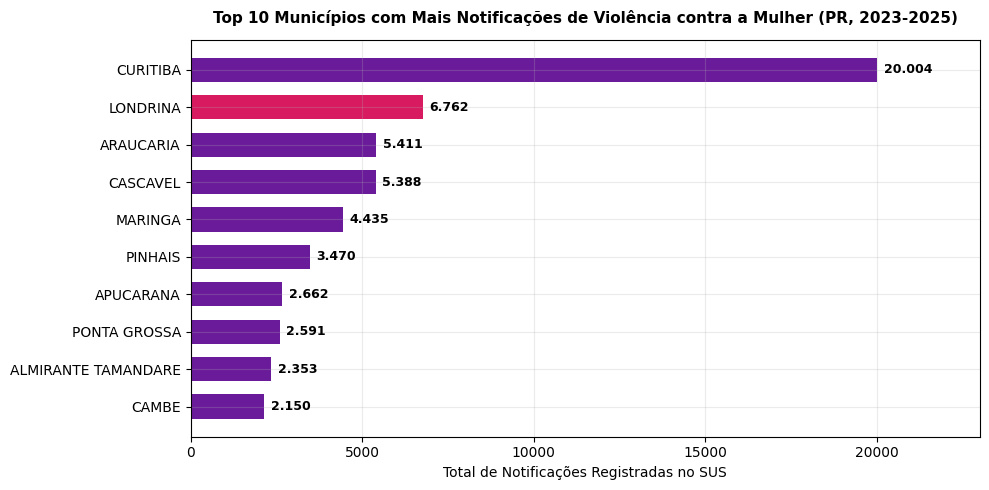

In [20]:
top10 = df.sort_values(by="total_notificacoes", ascending=False).head(10)
colors = ["#D81B60" if m == "LONDRINA" else "#6A1B9A" for m in top10["municipio"]]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top10["municipio"][::-1], top10["total_notificacoes"][::-1], color=colors[::-1], height=0.65)
ax.set_title("Top 10 Municípios com Mais Notificações de Violência contra a Mulher (PR, 2023-2025)", fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel("Total de Notificações Registradas no SUS", fontsize=10)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 200, bar.get_y() + bar.get_height()/2, f"{int(w):,}".replace(",", "."), va='center', fontsize=9, fontweight='bold')
ax.set_xlim(0, top10["total_notificacoes"].max() * 1.15)
plt.tight_layout()
plt.show()


**Frase de leitura do Gráfico 1:**  
*Londrina é o segundo maior polo de notificações de violência contra a mulher em todo o Paraná (6.762 ocorrências), liderando com folga o interior do estado e ficando atrás apenas da capital Curitiba (20.004).*


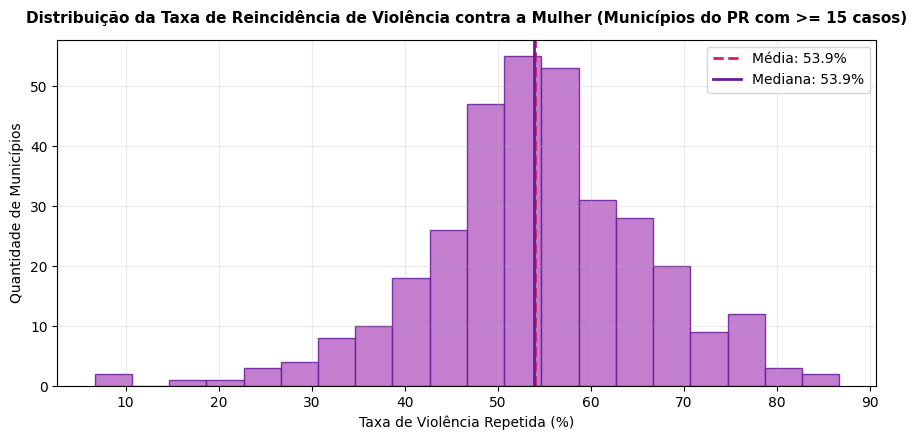

In [21]:
cidades_rep = df[df["total_notificacoes"] >= 15]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(cidades_rep["taxa_reincidencia_pct"], bins=20, color="#BA68C8", edgecolor="#6A1B9A", alpha=0.85)
ax.axvline(cidades_rep["taxa_reincidencia_pct"].mean(), color="#D81B60", linestyle='--', linewidth=2, label=f"Média: {cidades_rep['taxa_reincidencia_pct'].mean():.1f}%")
ax.axvline(cidades_rep["taxa_reincidencia_pct"].median(), color="#6A1B9A", linestyle='-', linewidth=2, label=f"Mediana: {cidades_rep['taxa_reincidencia_pct'].median():.1f}%")
ax.set_title("Distribuição da Taxa de Reincidência de Violência contra a Mulher (Municípios do PR com >= 15 casos)", fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel("Taxa de Violência Repetida (%)", fontsize=10)
ax.set_ylabel("Quantidade de Municípios", fontsize=10)
ax.legend(facecolor='white')
plt.tight_layout()
plt.show()


**Frase de leitura do Gráfico 2:**  
*A taxa de reincidência apresenta distribuição aproximadamente simétrica centrada em 53,5%, revelando que na grande maioria dos municípios paranaenses mais da metade das mulheres atendidas já sofreram agressões anteriores do mesmo agressor.*


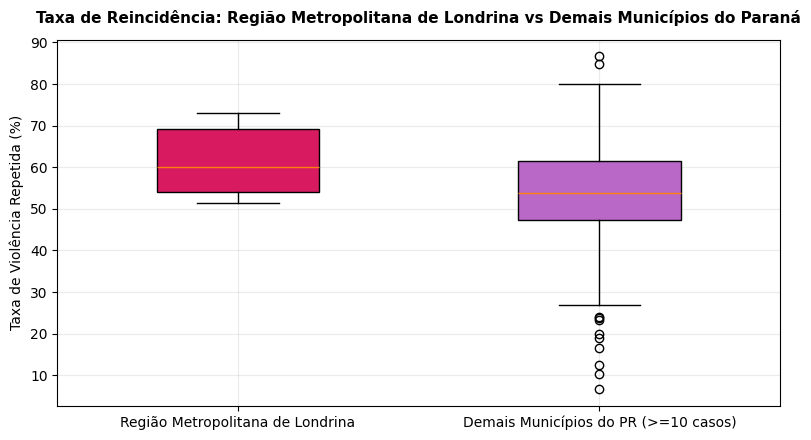

In [22]:
londrina_cidades = ["LONDRINA", "CAMBE", "APUCARANA", "ARAPONGAS", "ROLANDIA", "IBIPORA"]
d_reg = df[df["municipio"].isin(londrina_cidades)]["taxa_reincidencia_pct"]
d_out = df[(~df["municipio"].isin(londrina_cidades)) & (df["total_notificacoes"] >= 10)]["taxa_reincidencia_pct"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bp = ax.boxplot([d_reg, d_out], patch_artist=True, tick_labels=["Região Metropolitana de Londrina", "Demais Municípios do PR (>=10 casos)"], widths=0.45)
bp['boxes'][0].set_facecolor("#D81B60")
bp['boxes'][1].set_facecolor("#BA68C8")
ax.set_title("Taxa de Reincidência: Região Metropolitana de Londrina vs Demais Municípios do Paraná", fontsize=11, fontweight='bold', pad=12)
ax.set_ylabel("Taxa de Violência Repetida (%)", fontsize=10)
plt.tight_layout()
plt.show()


**Frase de leitura do Gráfico 3:**  
*A Região Metropolitana de Londrina apresenta taxa de reincidência mediana próxima a 60%, patamar superior à mediana do restante do estado (53,8%), com cidades vizinhas atingindo índices críticos superiores a 72% (Cambé e Ibiporã).*


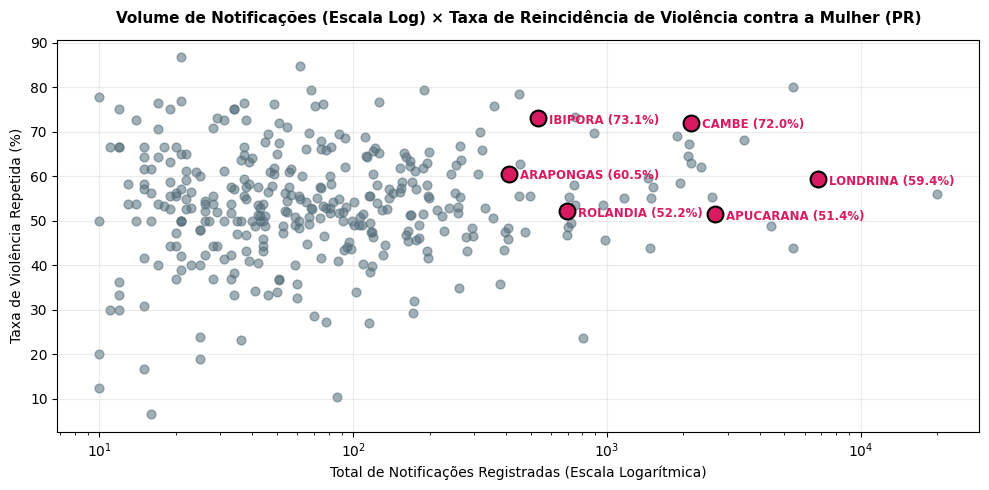

In [23]:
cidades_plot = df[df["total_notificacoes"] >= 10].copy()
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(cidades_plot["total_notificacoes"], cidades_plot["taxa_reincidencia_pct"], color="#546E7A", alpha=0.55, s=40, label="Municípios do PR")
for cid in ["LONDRINA", "CAMBE", "APUCARANA", "ARAPONGAS", "ROLANDIA", "IBIPORA"]:
    r = df[df["municipio"] == cid]
    if not r.empty:
        x, y = r["total_notificacoes"].values[0], r["taxa_reincidencia_pct"].values[0]
        ax.scatter(x, y, color="#D81B60", s=130, edgecolors='black', linewidth=1.5, zorder=5)
        ax.annotate(f"{cid} ({y:.1f}%)", (x, y), textcoords="offset points", xytext=(8, -4), fontsize=8.5, fontweight='bold', color="#D81B60")
ax.set_xscale('log')
ax.set_title("Volume de Notificações (Escala Log) × Taxa de Reincidência de Violência contra a Mulher (PR)", fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel("Total de Notificações Registradas (Escala Logarítmica)", fontsize=10)
ax.set_ylabel("Taxa de Violência Repetida (%)", fontsize=10)
plt.tight_layout()
plt.show()


**Frase de leitura do Gráfico 4:**  
*Mesmo em municípios de médio e grande porte onde o volume de registros é elevado (mais de 1.000 notificações), a taxa de repetição permanece cronicamente alta entre 50% e 72%, comprovando que o ciclo da violência persiste de forma homogênea nos centros urbanos.*


### Resposta a Três Perguntas com Números Reais

#### **Pergunta 1: Qual é o peso da Região Metropolitana de Londrina no panorama da violência contra a mulher no Paraná?**
* **Resposta com dados reais:** A Região Metropolitana de Londrina (abrangendo Londrina, Cambé, Apucarana, Arapongas, Rolândia e Ibiporã) acumulou **13.213 notificações oficiais de violência contra a mulher** no triênio 2023–2025. Isso representa expressivos **11,75% de todo o volume registrado no Estado do Paraná (112.443 casos)** em apenas seis municípios. Londrina isoladamente responde por **6.762 casos**, consolidando-se como a cidade com maior demanda de acolhimento protetivo fora da capital.

#### **Pergunta 2: Qual é a taxa real de reincidência (violência habitual/repetida) no estado e na região?**
* **Resposta com dados reais:** A taxa média estadual de violência repetida nos municípios com atendimento regular é de **53,77%** (mediana de 53,85%). Na Região de Londrina, a média ponderada atinge alarmantes **59,87%**: em Londrina a reincidência confirmada é de **59,38%** (2.910 casos reincidentes contra 1.991 isolados), atingindo picos ainda mais graves em **Cambé (72,02%)** e **Ibiporã (73,09%)**. Mais de 7 em cada 10 mulheres atendidas nesses municípios vizinhos já haviam sido agredidas previamente.

#### **Pergunta 3: Qual é o impacto da qualidade do preenchimento e da omissão de dados no sistema de saúde?**
* **Resposta com dados reais:** No Paraná, **18.452 notificações (16,41% do total)** não tiveram o campo de reincidência preenchido adequadamente pelos profissionais de saúde (17.066 marcadas como 'Ignorado' e 1.386 deixadas em branco). Em Londrina, o problema é agudo: **27,52% dos atendimentos (1.861 mulheres)** constam sem definição sobre a reincidência do agressor, comprovando que a subnotificação e o receio de retaliação dificultam o registro completo na ficha de atendimento inicial.

**Autor(a):** Mateus Zichack (GitHub: zichack)


## 6. Plano de Modelagem Preditiva e Avaliação (Entregas 3 e 4)
Conforme estabelecido no Documento Orientador (Seção 6.2), nesta Entrega 2 não é cobrado o treinamento de modelos, mas sim o planejamento teórico e arquitetural das próximas fases.

| Item do Plano | Definição da Equipe Rede Lilás |
|---|---|
| **Objetivo do Modelo no Aplicativo** | Estimar a probabilidade de reincidência de violência contra a usuária com base no perfil do agressor, histórico e contexto relacional, calibrando a régua de alerta na funcionalidade de *Autoavaliação de Risco* do aplicativo mobile camuflado. |
| **Variável-Alvo (`target`)** | Variável binária de reincidência: `1` (Violência Repetida / Reincidente) vs `0` (Episódio Isolado / Sem histórico prévio). |
| **Algoritmos Candidatos (Entrega 3)** | Regressão Logística (modelo baseline interpretável), Random Forest Classifier e XGBoost/LightGBM (modelos não-lineares para captura de interações complexas de risco). |
| **Métrica Primária de Avaliação** | **Recall / Sensibilidade (para a classe de alto risco):** Em um aplicativo de proteção à mulher vulnerável, o custo humano de um Falso Negativo (classificar uma mulher em risco iminente como situação segura) é inaceitável. O Recall deve ser priorizado sobre a acurácia global. |
| **Métricas Secundárias** | ROC-AUC (capacidade de discriminação global das faixas de risco), Precision e F1-Score balanceado. |
| **Estratégia de Validação** | Validação Cruzada Estratificada (*Stratified K-Fold*, $k=5$) garantindo que a proporção de casos reincidentes seja mantida em todas as partições de treino e teste. |
| **Integração com o Mobile (Entrega 4)** | O modelo treinado será exposto via API REST (FastAPI) ou integrado localmente, recebendo os inputs do quiz camuflado e disparando alertas e sugestão de contatos de confiança na tela de SOS. |

**Autor(a):** Samuel Augusto (GitHub: samuelaugusto)


## 7. Conclusões e Checklist de Entrega

O módulo de Data Science da Entrega 2 cumpriu integralmente os 7 requisitos exigidos pelo Documento Orientador, trabalhando sobre dados governamentais legítimos do Ministério da Saúde:
- [x] Base oficial pública do DataSUS/SINAN justificada e vinculada ao tema;
- [x] Ficha de governança, ética e conformidade LGPD preenchida sem dados pessoais de vítimas;
- [x] Dicionário de dados completo com tipos estatísticos e unidades;
- [x] Diagnóstico formal das 5 dimensões de qualidade de dados com contagens empíricas;
- [x] Tratamento de dados documentado em tabela Antes × Depois e base tratada salva em `dados/dados_tratados_datasus_pr.csv`;
- [x] Análise Exploratória (EDA) com medidas de tendência central, dispersão, assimetria, 4 gráficos com frases de leitura e 3 perguntas respondidas com dados reais;
- [x] Divisão equilibrada de autoria entre Mateus Zichack e Samuel Augusto;
- [x] Plano de modelagem preditiva e métricas estruturado para a Entrega 3.
